# Семинар 8. Метод Ньютона и квазиньютоновские методы

План:

1) Ньютон: демпфирование и модификация гессиана
2) Квазиньютоновские методы: DFP, BFGS, Barzilai–Borwein
3) L-BFGS: детали реализации
4) Сравнение с нелинейным методом сопряжённых градиентов

In [ ]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import cho_factor, cho_solve

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.figsize": (11, 4.2), "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 11, "lines.linewidth": 1.8, "figure.dpi": 110})

## 0. Оракул, трассировка, линейный поиск

Считаем вызовы оракула: сравнивать методы по числу итераций нечестно, итерация Ньютона
и итерация градиентного спуска стоят по-разному.

In [ ]:
class Oracle:
    def __init__(self, f, grad, hess=None):
        self._f, self._grad, self._hess = f, grad, hess
        self.reset()

    def reset(self):
        self.nf = self.ng = self.nh = 0

    def f(self, x):
        self.nf += 1
        return self._f(x)

    def grad(self, x):
        self.ng += 1
        return self._grad(x)

    def hess(self, x):
        self.nh += 1
        return self._hess(x)


class Trace:
    """(время, f, ||grad f||, число вызовов f, число вызовов grad)"""
    def __init__(self, name, oracle):
        self.name, self.oracle = name, oracle
        self.t0 = time.perf_counter()
        self.rows = []

    def add(self, f, gnorm):
        self.rows.append((time.perf_counter() - self.t0, f, gnorm,
                          self.oracle.nf, self.oracle.ng))

    def __getattr__(self, item):
        cols = {"t": 0, "fs": 1, "gs": 2, "nfs": 3, "ngs": 4}
        if item in cols:
            return np.array(self.rows)[:, cols[item]]
        raise AttributeError(item)

    @property
    def niter(self):
        return len(self.rows) - 1

Сильные условия Вульфа:

$$f(x + \alpha p) \le f(x) + c_1 \alpha \langle \nabla f(x), p\rangle, \qquad
|\langle \nabla f(x + \alpha p), p\rangle| \le c_2 |\langle \nabla f(x), p\rangle|.$$

Нужна именно сильная версия: без модуля в правом условии нелинейный CG теряет
направление спуска. Стандартная схема — расширение интервала, затем `zoom`.
Бесконечное значение `f` вне области определения обрабатывается как нарушение Армихо,
поэтому барьерные функции не требуют отдельного кода.

In [ ]:
def strong_wolfe(oracle, x, p, f0, g0, c1=1e-4, c2=0.9, a_init=1.0, max_iter=30):
    d0 = float(g0 @ p)
    if d0 >= 0:
        return None, None, None, None

    def probe(a):
        xa = x + a * p
        fa = oracle.f(xa)
        if not np.isfinite(fa):
            return xa, np.inf, None, None
        ga = oracle.grad(xa)
        return xa, fa, ga, float(ga @ p)

    def zoom(lo, hi, f_lo):
        a, xa, fa, ga = lo, x + lo * p, f_lo, None
        for _ in range(max_iter):
            a = 0.5 * (lo + hi)
            xa, fa, ga, da = probe(a)
            if fa > f0 + c1 * a * d0 or fa >= f_lo:
                hi = a
            else:
                if abs(da) <= -c2 * d0:
                    return a, xa, fa, ga
                if da * (hi - lo) >= 0:
                    hi = lo
                lo, f_lo = a, fa
            if abs(hi - lo) < 1e-15:
                break
        return a, xa, fa, ga

    a_prev, f_prev, a = 0.0, f0, a_init
    for i in range(max_iter):
        xa, fa, ga, da = probe(a)
        if fa > f0 + c1 * a * d0 or (i > 0 and fa >= f_prev):
            return zoom(a_prev, a, f_prev)
        if abs(da) <= -c2 * d0:
            return a, xa, fa, ga
        if da >= 0:
            return zoom(a, a_prev, fa)
        a_prev, f_prev, a = a, fa, 2 * a
    return a, xa, fa, ga

Общий цикл спуска. Метод задаётся тремя функциями: начальная длина шага,
направление и обновление внутреннего состояния по паре $(s_k, y_k)$.

In [ ]:
def armijo(oracle, x, p, f0, g0, c1=1e-4, rho=0.5, a_init=1.0, max_iter=60):
    """Только условие достаточного убывания: условия кривизны нет."""
    d0 = float(g0 @ p)
    if d0 >= 0:
        return None, None, None, None
    a = a_init
    for _ in range(max_iter):
        xa = x + a * p
        fa = oracle.f(xa)
        if np.isfinite(fa) and fa <= f0 + c1 * a * d0:
            return a, xa, fa, oracle.grad(xa)
        a *= rho
    return None, None, None, None


class DescentMethod:
    name = "method"
    c2 = 0.9
    search = "wolfe"

    def init_state(self, x, g):
        pass

    def alpha_init(self, k, x, g, p):
        return 1.0

    def direction(self, x, g):
        raise NotImplementedError

    def update(self, s, y, x, g):
        pass

    def solve(self, oracle, x0, tol=1e-6, max_iter=500):
        x = np.array(x0, dtype=float)
        f, g = oracle.f(x), oracle.grad(x)
        tr = Trace(self.name, oracle)
        tr.add(f, np.linalg.norm(g))
        self.init_state(x, g)
        self.alpha_hist = []
        for k in range(max_iter):
            if np.linalg.norm(g) <= tol:
                break
            p = self.direction(x, g)
            ls = strong_wolfe if self.search == "wolfe" else armijo
            kw = {"c2": self.c2} if self.search == "wolfe" else {}
            a, xn, fn, gn = ls(oracle, x, p, f, g,
                               a_init=self.alpha_init(k, x, g, p), **kw)
            if a is None or a < 1e-16 or gn is None:
                break
            if fn >= f - 1e-15 * abs(f):     # прогресса по функции больше нет
                break
            self.alpha_hist.append(a)
            self.update(xn - x, gn - g, xn, gn)
            x, f, g = xn, fn, gn
            tr.add(f, np.linalg.norm(g))
        return x, tr


def report(traces):
    print(f"{'метод':>16} {'итер':>6} {'f':>14} {'||g||':>10} {'calls f':>8} "
          f"{'calls g':>8} {'время, с':>9}")
    for tr in traces:
        print(f"{tr.name:>16} {tr.niter:6d} {tr.fs[-1]:14.6e} {tr.gs[-1]:10.2e} "
              f"{int(tr.nfs[-1]):8d} {int(tr.ngs[-1]):8d} {tr.t[-1]:9.2f}")


def plot_traces(traces, xaxis="iter", ylim=None, title=None, ax=None):
    ax = ax or plt.gca()
    for tr in traces:
        xs = {"iter": np.arange(len(tr.gs)), "calls": tr.nfs + tr.ngs, "time": tr.t}[xaxis]
        ax.semilogy(xs, np.maximum(tr.gs, 1e-18), label=tr.name)
    ax.set_xlabel({"iter": "итерация", "calls": "вызовов оракула",
                   "time": "время, с"}[xaxis])
    ax.set_ylabel(r"$\|\nabla f(x_k)\|$")
    if ylim:
        ax.set_ylim(*ylim)
    if title:
        ax.set_title(title)
    ax.legend(fontsize=9)

## 1. Метод Ньютона

$$x_{k+1} = x_k - \alpha_k [\nabla^2 f(x_k)]^{-1}\nabla f(x_k).$$

Направление ищем решением системы, а не обращением матрицы: разложение Холецкого
стоит $\tfrac{1}{3}n^3$ против $2n^3$ у явного обратного и заодно проверяет
положительную определённость. Если разложение упало, гессиан модифицируем:
$\nabla^2 f + \tau I$ с удвоением $\tau$, пока Холецкий не пройдёт.

In [ ]:
class Newton(DescentMethod):
    def __init__(self, name="Newton", modify=True, damped=True):
        self.name, self.modify, self.damped = name, modify, damped
        self.tau_hist = []

    def alpha_init(self, k, x, g, p):
        return 1.0

    def direction(self, x, g):
        H = self.oracle.hess(x)
        if not self.modify:
            self.tau_hist.append(0.0)
            return -np.linalg.solve(H, g)
        tau = 0.0
        diag_min = np.min(np.diag(H))
        if diag_min <= 0:
            tau = 1e-3 - diag_min
        for _ in range(40):
            try:
                c = cho_factor(H + tau * np.eye(H.shape[0]), lower=True)
                self.tau_hist.append(tau)
                return -cho_solve(c, g)
            except np.linalg.LinAlgError:
                tau = max(2 * tau, 1e-3)
        raise RuntimeError("не удалось модифицировать гессиан")

    def solve(self, oracle, x0, tol=1e-6, max_iter=500):
        self.oracle = oracle
        if not self.damped:                      # чистый шаг alpha = 1
            x = np.array(x0, dtype=float)
            f, g = oracle.f(x), oracle.grad(x)
            tr = Trace(self.name, oracle)
            tr.add(f, np.linalg.norm(g))
            for _ in range(max_iter):
                if np.linalg.norm(g) <= tol or not np.isfinite(f):
                    break
                x = x + self.direction(x, g)
                f, g = oracle.f(x), oracle.grad(x)
                tr.add(f, np.linalg.norm(g))
            return x, tr
        return super().solve(oracle, x0, tol, max_iter)

### 1.1. Аналитический центр системы неравенств

$$f(x) = -\sum_{i=1}^m \log(1 - a_i^\top x) - \sum_{i=1}^n \log(1 - x_i^2) \to \min_x$$

Градиент и гессиан выписываем аналитически; автодифференцирование здесь только
замедлило бы и скрыло структуру $A D A^\top$.

In [ ]:
def analytic_center(A):
    """A: (n, m), столбцы — векторы a_i."""
    n = A.shape[0]

    def f(x):
        u, v = 1 - A.T @ x, 1 - x ** 2
        if np.any(u <= 0) or np.any(v <= 0):
            return np.inf
        return -np.sum(np.log(u)) - np.sum(np.log(v))

    def grad(x):
        u, v = 1 - A.T @ x, 1 - x ** 2
        return A @ (1 / u) + 2 * x / v

    def hess(x):
        u, v = 1 - A.T @ x, 1 - x ** 2
        return (A / u ** 2) @ A.T + np.diag(2 * (1 + x ** 2) / v ** 2)

    return Oracle(f, grad, hess), n


np.random.seed(0)
n, m, aniso = 300, 600, 30.0
# строки A растянуты на полтора порядка: иначе задача слишком лёгкая и все методы
# выглядят одинаково
A = (np.random.randn(n, m) * np.logspace(0, np.log10(aniso), n)[:, None]) / np.sqrt(n)
oracle_ac, _ = analytic_center(A)
x0_ac = np.zeros(n)
print("f(x0) =", oracle_ac.f(x0_ac), " ||grad f(x0)|| =", np.linalg.norm(oracle_ac.grad(x0_ac)))

f(x0) = -0.0  ||grad f(x0)|| = 255.16386389094149


### 1.2. Зачем нужно демпфирование

Выпуклости и гладкости для шага $\alpha = 1$ недостаточно. Канонический пример:

$$f(x) = \sqrt{1 + x^2}, \qquad
x_{k+1} = x_k - \frac{f'(x_k)}{f''(x_k)} = x_k - x_k(1 + x_k^2) = -x_k^3.$$

Функция выпукла и бесконечно гладка, но чистый Ньютон сходится только при
$|x_0| < 1$ и расходится кубически при $|x_0| > 1$.

In [ ]:
soft = Oracle(lambda x: float(np.sqrt(1 + x[0] ** 2)),
              lambda x: np.array([x[0] / np.sqrt(1 + x[0] ** 2)]),
              lambda x: np.array([[(1 + x[0] ** 2) ** -1.5]]))

for x0_ in [0.9, 1.1]:
    for damped in [False, True]:
        soft.reset()
        meth = Newton("", damped=damped)
        x, tr = meth.solve(soft, np.array([x0_]), tol=1e-10, max_iter=12)
        tail = np.array2string(tr.fs[:6], precision=4)
        print(f"x0 = {x0_}, {'Вульф ' if damped else 'alpha=1'}: "
              f"итераций {tr.niter:2d}, f = {tr.fs[-1]:.6g}, f_k = {tail}")

x0 = 0.9, alpha=1: итераций  5, f = 1, f_k = [1.3454 1.2375 1.0724 1.0017 1.     1.    ]
x0 = 0.9, Вульф : итераций  5, f = 1, f_k = [1.3454 1.2375 1.0724 1.0017 1.     1.    ]
x0 = 1.1, alpha=1: итераций  8, f = inf, f_k = [1.4866e+00 1.6648e+00 2.5612e+00 1.3148e+01 2.2532e+03 1.1440e+10]
x0 = 1.1, Вульф : итераций  3, f = 1, f_k = [1.4866 1.0066 1.     1.    ]


Линейный поиск срезает первый шаг и возвращает метод в область сходимости.
Для барьерной функции история та же, только резче: полный шаг может выбросить
за границу области определения, где $f = +\infty$; условие Армихо такой шаг
отвергает автоматически.

In [ ]:
m_ = Newton("Newton")
oracle_ac.reset()
_, tr_newton = m_.solve(oracle_ac, x0_ac, tol=1e-10, max_iter=100)
print("длины шага по итерациям:", np.round(m_.alpha_hist, 4))
print("||grad f|| по итерациям:", np.array2string(tr_newton.gs, precision=2))

длины шага по итерациям: [1. 1. 1. 1. 1. 1.]
||grad f|| по итерациям: [255.16 121.92  50.29   8.3    0.73   0.01   0.  ]


На аналитическом центре поиск не вмешался ни разу: полный шаг принимается
с самого начала, и норма градиента падает с квадратичной скоростью — число
верных знаков удваивается за итерацию. Демпфирование здесь ничего не стоит,
это страховка на случай плохого старта.

### 1.3. Модификация гессиана на невыпуклой задаче

Функция Розенброка невыпукла, и в начале траектории гессиан знаконеопределён.
Без модификации ньютоновское направление перестаёт быть направлением спуска.

In [ ]:
def rosenbrock_oracle(a=1.0, b=100.0):
    f = lambda x: (a - x[0]) ** 2 + b * (x[1] - x[0] ** 2) ** 2
    grad = lambda x: np.array([-2 * (a - x[0]) - 4 * b * x[0] * (x[1] - x[0] ** 2),
                               2 * b * (x[1] - x[0] ** 2)])
    hess = lambda x: np.array([[2 - 4 * b * (x[1] - 3 * x[0] ** 2), -4 * b * x[0]],
                               [-4 * b * x[0], 2 * b]])
    return Oracle(f, grad, hess)


rose = rosenbrock_oracle()
for x0_r in [np.array([-1.2, 1.0]), np.array([0.0, 1.0])]:
    ev = np.linalg.eigvalsh(rose.hess(x0_r))
    print(f"x0 = {x0_r}, спектр гессиана {np.round(ev, 1)}, "
          f"{'положительно определён' if ev[0] > 0 else 'ЗНАКОНЕОПРЕДЕЛЁН'}")
    for mod in [False, True]:
        rose.reset()
        meth = Newton(f"Newton, modify={mod}", modify=mod)
        x, tr = meth.solve(rose, x0_r, tol=1e-8, max_iter=200)
        print(f"    modify={mod!s:>5}: итераций {tr.niter:3d}, x = {np.round(x, 4)}, "
              f"||g|| = {tr.gs[-1]:.2e}, max tau = {max(meth.tau_hist):.4g}")

x0 = [-1.2  1. ], спектр гессиана [  23.6 1506.4], положительно определён
    modify=False: итераций  21, x = [1. 1.], ||g|| = 1.22e-10, max tau = 0
    modify= True: итераций  21, x = [1. 1.], ||g|| = 1.22e-10, max tau = 0
x0 = [0. 1.], спектр гессиана [-398.  200.], ЗНАКОНЕОПРЕДЕЛЁН
    modify=False: итераций  15, x = [1. 1.], ||g|| = 5.84e-10, max tau = 0
    modify= True: итераций   4, x = [1. 1.], ||g|| = 7.24e-14, max tau = 398


## 2. Квазиньютоновские методы

Секущее уравнение: аппроксимация $B_{k+1}$ гессиана должна воспроизводить
наблюдённое изменение градиента

$$B_{k+1}s_k = y_k, \qquad s_k = x_{k+1}-x_k,\quad y_k = \nabla f(x_{k+1}) - \nabla f(x_k).$$

Решение не единственно, разные способы доопределения дают DFP и BFGS.
Работаем сразу с $H_k \approx [\nabla^2 f]^{-1}$, чтобы не решать систему.

$$H^{\text{DFP}}_{k+1} = H_k - \frac{H_k y_k y_k^\top H_k}{y_k^\top H_k y_k}
+ \frac{s_k s_k^\top}{y_k^\top s_k}$$

$$H^{\text{BFGS}}_{k+1} = (I - \rho_k s_k y_k^\top)H_k(I - \rho_k y_k s_k^\top)
+ \rho_k s_k s_k^\top, \qquad \rho_k = \frac{1}{y_k^\top s_k}$$

Обе формулы сохраняют положительную определённость тогда и только тогда, когда
$y_k^\top s_k > 0$ — это условие кривизны, и оно автоматически выполнено,
если шаг удовлетворяет условиям Вульфа.

In [ ]:
class QuasiNewton(DescentMethod):
    """H — приближение обратного гессиана; skip пропускает обновление при y's <= 0."""
    def __init__(self, kind="BFGS", name=None, skip=True, track_cond=False):
        self.kind, self.skip, self.track_cond = kind, skip, track_cond
        self.name = name or kind
        self.n_skipped = 0

    def init_state(self, x, g):
        self.H = np.eye(x.size)
        self.first = True
        self.n_skipped = 0
        self.cond_hist = []

    def direction(self, x, g):
        return -self.H @ g

    def update(self, s, y, x, g):
        ys = float(y @ s)
        if ys <= 1e-12 * np.linalg.norm(s) * np.linalg.norm(y):
            self.n_skipped += 1
            if self.skip:
                return
            ys = 1e-12
        if self.first:                       # масштабирование H0 по первой паре
            self.H *= ys / float(y @ y)
            self.first = False
        if self.kind == "BFGS":
            # H <- (I - rho s y')H(I - rho y s') + rho s s', но в раскрытом виде:
            # запись «в лоб» через V даёт два матричных умножения, то есть O(n^3)
            rho = 1.0 / ys
            Hy = self.H @ y
            self.H += (-rho * (np.outer(Hy, s) + np.outer(s, Hy))
                       + (rho ** 2 * float(y @ Hy) + rho) * np.outer(s, s))
        elif self.kind == "DFP":
            Hy = self.H @ y
            self.H = (self.H - np.outer(Hy, Hy) / float(y @ Hy)
                      + np.outer(s, s) / ys)
        else:
            raise ValueError(self.kind)
        if self.track_cond:
            self.cond_hist.append(np.linalg.cond(self.H))

### 2.1. Barzilai–Borwein

Самое дешёвое приближение: $H_k = \gamma_k I$, где $\gamma_k$ подбирается
из секущего уравнения в смысле наименьших квадратов.

$$\gamma^{\mathrm{I}}_k = \frac{s_{k-1}^\top s_{k-1}}{s_{k-1}^\top y_{k-1}},
\qquad
\gamma^{\mathrm{II}}_k = \frac{s_{k-1}^\top y_{k-1}}{y_{k-1}^\top y_{k-1}}.$$

Памяти $O(n)$, матриц нет вообще. Классический BB идёт без линейного поиска
и немонотонно; здесь оставляем Вульфа, чтобы сравнение было честным.

In [ ]:
class BB(DescentMethod):
    def __init__(self, variant="I", name=None):
        self.variant = variant
        self.name = name or f"BB {variant}"

    def init_state(self, x, g):
        self.gamma = None

    def alpha_init(self, k, x, g, p):
        return 1.0

    def direction(self, x, g):
        return -g if self.gamma is None else -self.gamma * g

    def update(self, s, y, x, g):
        ys = float(y @ s)
        if ys <= 0:
            self.gamma = None
            return
        self.gamma = (float(s @ s) / ys if self.variant == "I"
                      else ys / float(y @ y))

## 3. L-BFGS: детали реализации

Матрицу $H_k$ не храним — храним $m$ последних пар $(s_i, y_i)$ и восстанавливаем
произведение $H_k \nabla f(x_k)$ двухпетлевой рекурсией.

Четыре места, где реализация обычно ломается:

1) **Масштабирование $H_k^0$.** Между петлями берём $H_k^0 = \gamma_k I$ с
   $\gamma_k = \dfrac{s_{k-1}^\top y_{k-1}}{y_{k-1}^\top y_{k-1}}$, а не $I$.
   Это подстройка под текущий масштаб задачи, именно она отличает L-BFGS
   от «обрезанного BFGS».
2) **Условие кривизны.** Пару с $s^\top y \le 0$ в историю не кладём.
3) **Начальная длина шага.** Всегда пробуем $\alpha = 1$.
4) **Хранение.** Кольцевой буфер; $\rho_i$ считаем один раз при добавлении пары.

In [ ]:
class LBFGS(DescentMethod):
    def __init__(self, m=10, scale=True, skip=True, name=None):
        self.m, self.scale, self.skip = m, scale, skip
        self.name = name or f"L-BFGS, m={m}"

    def init_state(self, x, g):
        self.S, self.Y, self.rho = [], [], []
        self.n_skipped = 0

    def two_loop(self, g):
        q = g.copy()
        alphas = []
        for s, y, rho in zip(reversed(self.S), reversed(self.Y), reversed(self.rho)):
            a = rho * float(s @ q)
            q -= a * y
            alphas.append(a)
        gamma = 1.0
        if self.S and self.scale:
            s, y = self.S[-1], self.Y[-1]
            gamma = float(s @ y) / float(y @ y)
        r = gamma * q
        for (s, y, rho), a in zip(zip(self.S, self.Y, self.rho), reversed(alphas)):
            b = rho * float(y @ r)
            r += (a - b) * s
        return r

    def direction(self, x, g):
        if not self.S:
            return -g / max(np.linalg.norm(g), 1.0)
        return -self.two_loop(g)

    def update(self, s, y, x, g):
        ys = float(y @ s)
        if ys <= 1e-12 * np.linalg.norm(s) * np.linalg.norm(y):
            self.n_skipped += 1
            if self.skip:
                return
        self.S.append(s)
        self.Y.append(y)
        self.rho.append(1.0 / ys)
        if len(self.S) > self.m:
            self.S.pop(0)
            self.Y.pop(0)
            self.rho.pop(0)

### 3.1. Проверка: двухпетлевая рекурсия против явной матрицы

Если выключить масштабирование ($H^0 = I$) и взять $m = \infty$, двухпетлевая
рекурсия обязана давать в точности тот же вектор, что и явная BFGS-матрица.
Это первое, что надо проверять при отладке.

In [ ]:
np.random.seed(3)
n_t = 40
S = [np.random.randn(n_t) for _ in range(12)]
Y = [s * (1.5 + np.random.rand()) + 0.1 * np.random.randn(n_t) for s in S]
Y = [y if y @ s > 0 else -y for s, y in zip(S, Y)]      # обеспечиваем s'y > 0

H = np.eye(n_t)
for s, y in zip(S, Y):
    rho = 1.0 / (y @ s)
    V = np.eye(n_t) - rho * np.outer(s, y)
    H = V @ H @ V.T + rho * np.outer(s, s)

lb = LBFGS(m=100, scale=False)
lb.init_state(np.zeros(n_t), np.zeros(n_t))
for s, y in zip(S, Y):
    lb.update(s, y, None, None)

g_test = np.random.randn(n_t)
print("||H g - two_loop(g)|| =", np.linalg.norm(H @ g_test - lb.two_loop(g_test)))

||H g - two_loop(g)|| = 4.9379043149067125e-15


### 3.2. Вторая тестовая задача: логистическая регрессия

Первая — уже введённый аналитический центр: там есть гессиан, поэтому можно
держать Ньютона как эталон. Вторая — логистическая регрессия

$$f(w) = \frac1N\sum_{i=1}^N \log\bigl(1 + e^{-y_i \langle a_i, w\rangle}\bigr)
+ \frac{\lambda}{2}\|w\|_2^2$$

Признаки делаем скоррелированными, иначе задача слишком лёгкая и все методы
выглядят одинаково.

In [ ]:
def logreg_oracle(Adata, labels, lam):
    N = Adata.shape[0]

    def f(w):
        z = -labels * (Adata @ w)
        return np.mean(np.logaddexp(0, z)) + 0.5 * lam * w @ w

    def grad(w):
        z = -labels * (Adata @ w)
        sig = 0.5 * (1.0 + np.tanh(0.5 * z))      # устойчивый сигмоид
        return -(Adata.T @ (labels * sig)) / N + lam * w

    return Oracle(f, grad)


np.random.seed(7)
N, d = 4000, 1500
Z = np.random.randn(N, d)
decay = 1.0 / np.sqrt(np.arange(1, d + 1))          # спектр с медленным спадом
Adata = (Z * decay) + 0.5 * Z[:, [0]]               # общий фактор => корреляция
w_true = np.random.randn(d) / np.sqrt(d)
labels = np.sign(Adata @ w_true + 0.3 * np.random.randn(N))
lam = 1e-3
oracle_lr = logreg_oracle(Adata, labels, lam)
w0 = np.zeros(d)
print("N =", N, " d =", d, " f(w0) =", oracle_lr.f(w0))

N = 4000  d = 1500  f(w0) = 0.6931471805599454


### 3.3. Масштабирование $H^0_k$

Выключаем единственную строчку `gamma = (s'y)/(y'y)` и смотрим на разницу.

In [ ]:
traces_scale = []
for meth in [LBFGS(m=10, scale=False, name="m=10, H0 = I"),
             LBFGS(m=10, name="m=10, H0 = gamma I"),
             LBFGS(m=50, scale=False, name="m=50, H0 = I"),
             LBFGS(m=50, name="m=50, H0 = gamma I")]:
    oracle_ac.reset()
    _, tr = meth.solve(oracle_ac, x0_ac, tol=1e-7, max_iter=600)
    traces_scale.append(tr)
report(traces_scale)

           метод   итер              f      ||g||  calls f  calls g  время, с
    m=10, H0 = I    401  -2.010759e+02   8.27e-05     4384     3244      0.58
m=10, H0 = gamma I    319  -2.010759e+02   2.17e-05      339      337      0.07
    m=50, H0 = I    600  -2.010759e+02   2.91e-04     5950     4674      0.89
m=50, H0 = gamma I    274  -2.010759e+02   1.09e-05      293      291      0.16


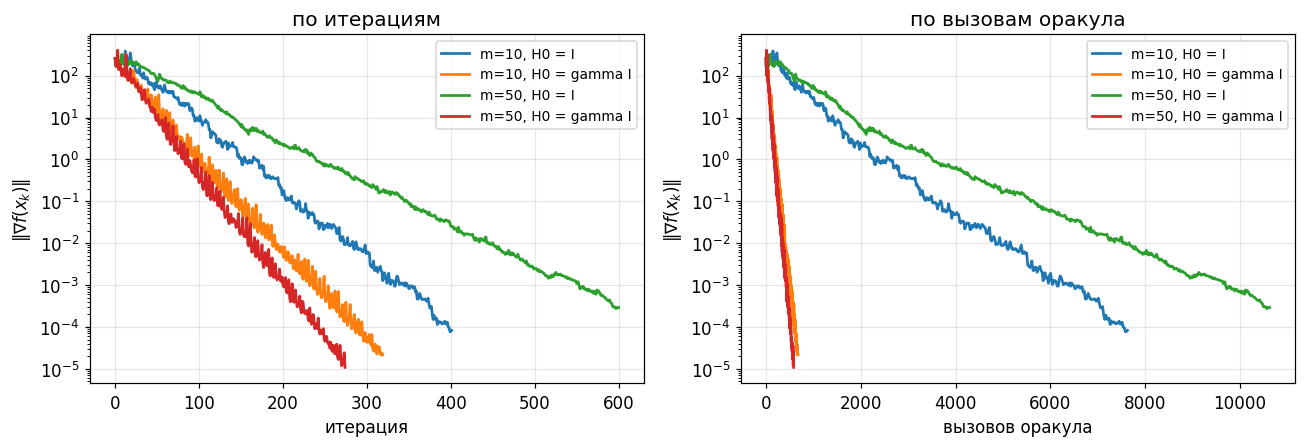

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
plot_traces(traces_scale, "iter", title="по итерациям", ax=axes[0])
plot_traces(traces_scale, "calls", title="по вызовам оракула", ax=axes[1])
plt.tight_layout()

Одна строчка кода меняет и число итераций, и стоимость линейного поиска:
без масштабирования начальная длина шага $\alpha = 1$ систематически не подходит,
и поиск каждый раз её подбирает заново.

### 3.3.1. Длина памяти $m$

In [ ]:
traces_m = []
for meth in [LBFGS(m=1, name="m=1"), LBFGS(m=3, name="m=3"), LBFGS(m=10, name="m=10"),
             LBFGS(m=30, name="m=30"), LBFGS(m=100, name="m=100")]:
    oracle_lr.reset()
    _, tr = meth.solve(oracle_lr, w0, tol=1e-7, max_iter=400)
    traces_m.append(tr)
report(traces_m)

           метод   итер              f      ||g||  calls f  calls g  время, с
             m=1    400   5.209777e-01   2.12e-03      635      635      1.75
             m=3    400   5.209332e-01   8.17e-05      592      592      1.84
            m=10    400   5.209331e-01   1.21e-06      656      656      1.85
            m=30    275   5.209331e-01   9.01e-08      402      402      1.19
           m=100    133   5.209331e-01   9.44e-08      141      141      0.65


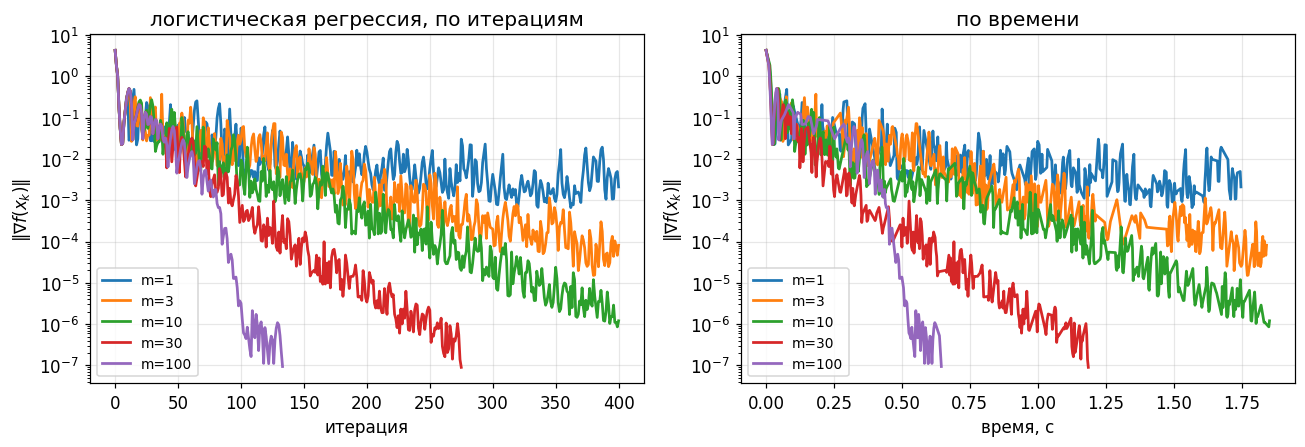

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
plot_traces(traces_m, "iter", title="логистическая регрессия, по итерациям", ax=axes[0])
plot_traces(traces_m, "time", title="по времени", ax=axes[1])
plt.tight_layout()

Здесь рост $m$ окупается вплоть до $m = 100$: одна итерация стоит $O(mn)$, а
один вызов оракула — $O(Nd)$, и при $N \gg m$ хранение истории почти бесплатно.
Предел наступает, когда $m$ сравнимо с числом обусловленности задачи или когда
оракул дёшев: тогда двухпетлевая рекурсия становится главной статьёй расходов.
Стандартный рабочий диапазон $m \in [5, 20]$ — компромисс по памяти, а не по
скорости сходимости.

### 3.4. Сколько шагов принимается с $\alpha = 1$

Практический признак того, что приближение гессиана адекватно: линейному поиску
почти не приходится вмешиваться.

In [ ]:
for meth in [LBFGS(m=10), QuasiNewton("BFGS"), BB("I"), BB("II")]:
    oracle_lr.reset()
    meth.solve(oracle_lr, w0, tol=1e-6, max_iter=200)
    a = np.array(meth.alpha_hist)
    print(f"{meth.name:>10}: доля шагов alpha=1 — {np.mean(np.isclose(a, 1)):.2f}, "
          f"медиана alpha = {np.median(a):.3g}")

L-BFGS, m=10: доля шагов alpha=1 — 0.82, медиана alpha = 1
      BFGS: доля шагов alpha=1 — 0.99, медиана alpha = 1
      BB I: доля шагов alpha=1 — 0.56, медиана alpha = 1
     BB II: доля шагов alpha=1 — 0.45, медиана alpha = 1


### 3.5. Цена итерации: O(n^2) против O(mn)

BFGS хранит и обновляет плотную матрицу. Замеряем время одного обновления.

In [ ]:
sizes = [500, 1000, 2000, 4000]
t_bfgs, t_lbfgs = [], []
for nn in sizes:
    s, y = np.random.randn(nn), np.random.randn(nn)
    y = y if y @ s > 0 else -y
    H = np.eye(nn)
    qn = QuasiNewton("BFGS")
    qn.H, qn.first = H, False
    qn.update(s, y, None, None)                      # прогрев
    t = time.perf_counter()
    for _ in range(20):
        qn.update(s, y, None, None)
    t_bfgs.append((time.perf_counter() - t) / 20)

    lb = LBFGS(m=10)
    lb.init_state(np.zeros(nn), np.zeros(nn))
    for _ in range(10):
        lb.update(s + np.random.randn(nn) * 1e-3, y, None, None)
    g = np.random.randn(nn)
    lb.two_loop(g)
    t = time.perf_counter()
    for _ in range(20):
        lb.two_loop(g)
    t_lbfgs.append((time.perf_counter() - t) / 20)

print(f"{'n':>6} {'BFGS update, мс':>17} {'L-BFGS two-loop, мс':>21} {'память BFGS':>14}")
for nn, tb, tl in zip(sizes, t_bfgs, t_lbfgs):
    print(f"{nn:6d} {1e3 * tb:17.3f} {1e3 * tl:21.3f} {nn ** 2 * 8 / 2 ** 20:11.1f} МБ")
print("\nдля n = 10^5 плотная матрица H заняла бы",
      round(1e10 * 8 / 2 ** 30), "ГБ — BFGS неприменим")

     n   BFGS update, мс   L-BFGS two-loop, мс    память BFGS
   500             2.059                 0.081         1.9 МБ
  1000             7.684                 0.059         7.6 МБ
  2000            32.988                 0.073        30.5 МБ
  4000           203.738                 0.125       122.1 МБ

для n = 10^5 плотная матрица H заняла бы 75 ГБ — BFGS неприменим


## 4. Сравнение с нелинейным методом сопряжённых градиентов

$$p_{k} = -\nabla f(x_k) + \beta_k p_{k-1}$$

$$\beta^{FR}_k = \frac{\|\nabla f(x_k)\|^2}{\|\nabla f(x_{k-1})\|^2}, \qquad
\beta^{PR}_k = \frac{\langle \nabla f(x_k), \nabla f(x_k)-\nabla f(x_{k-1})\rangle}
{\|\nabla f(x_{k-1})\|^2}, \qquad
\beta^{PR+}_k = \max(\beta^{PR}_k, 0).$$

Детали, без которых CG не работает:

1) $\beta^{PR+}$: обнуление $\beta$ — это автоматический рестарт, он же гарантия
   направления спуска;
2) $c_2 \approx 0.1$ вместо $0.9$: при большом $c_2$ направление FR перестаёт быть
   направлением спуска;
3) начальная длина шага не $1$, а
   $\alpha_{k} = \alpha_{k-1}\dfrac{\langle \nabla f(x_{k-1}), p_{k-1}\rangle}
   {\langle \nabla f(x_k), p_k\rangle}$ — у CG нет естественного масштаба;
4) защитный рестарт при потере направления спуска.

In [ ]:
class NonlinearCG(DescentMethod):
    def __init__(self, variant="PR+", restart=None, c2=0.1, name=None):
        self.variant, self.restart, self.c2 = variant, restart, c2
        self.name = name or f"CG {variant}"

    def init_state(self, x, g):
        self.p = None
        self.g_prev = None
        self.a_prev = None
        self.dphi_prev = None
        self.k = 0
        self.n_restart = 0

    def direction(self, x, g):
        if self.p is None or (self.restart and self.k % self.restart == 0):
            self.p = -g
        else:
            gg = float(self.g_prev @ self.g_prev)
            if self.variant == "FR":
                beta = float(g @ g) / gg
            else:
                beta = float(g @ (g - self.g_prev)) / gg
                if self.variant == "PR+":
                    beta = max(beta, 0.0)
            p = -g + beta * self.p
            if float(g @ p) >= 0:                   # не спуск — рестарт
                p = -g
                self.n_restart += 1
            self.p = p
        self.g_prev = g.copy()
        self.k += 1
        return self.p

    def alpha_init(self, k, x, g, p):
        dphi = float(g @ p)
        if self.a_prev is None or dphi == 0:
            a = 1.0 / max(np.linalg.norm(g), 1e-12)
        else:
            a = self.a_prev * self.dphi_prev / dphi
        self.dphi_prev = dphi
        self.a_prev = a
        return min(max(a, 1e-12), 1e6)

    def update(self, s, y, x, g):
        self.a_prev = np.linalg.norm(s) / max(np.linalg.norm(self.p), 1e-12)

### 4.1. Логистическая регрессия: CG против L-BFGS

In [ ]:
methods = [NonlinearCG("FR"),
           NonlinearCG("PR+"),
           NonlinearCG("PR+", restart=50, name="CG PR+, рестарт 50"),
           LBFGS(m=10),
           QuasiNewton("BFGS"),
           BB("II")]
traces_cmp = []
for meth in methods:
    oracle_lr.reset()
    _, tr = meth.solve(oracle_lr, w0, tol=1e-7, max_iter=500)
    traces_cmp.append(tr)
report(traces_cmp)

           метод   итер              f      ||g||  calls f  calls g  время, с
           CG FR    353   5.209331e-01   1.07e-07     1939     1939      5.58
          CG PR+    323   5.209331e-01   6.48e-08     2157     2157      6.29
CG PR+, рестарт 50    329   5.209331e-01   1.76e-07     2016     2016      5.64
    L-BFGS, m=10    468   5.209331e-01   9.56e-08      772      772      2.30
            BFGS    363   5.209331e-01   1.04e-07      370      370      9.74
           BB II    500   5.210737e-01   6.16e-04     1589     1589      4.64


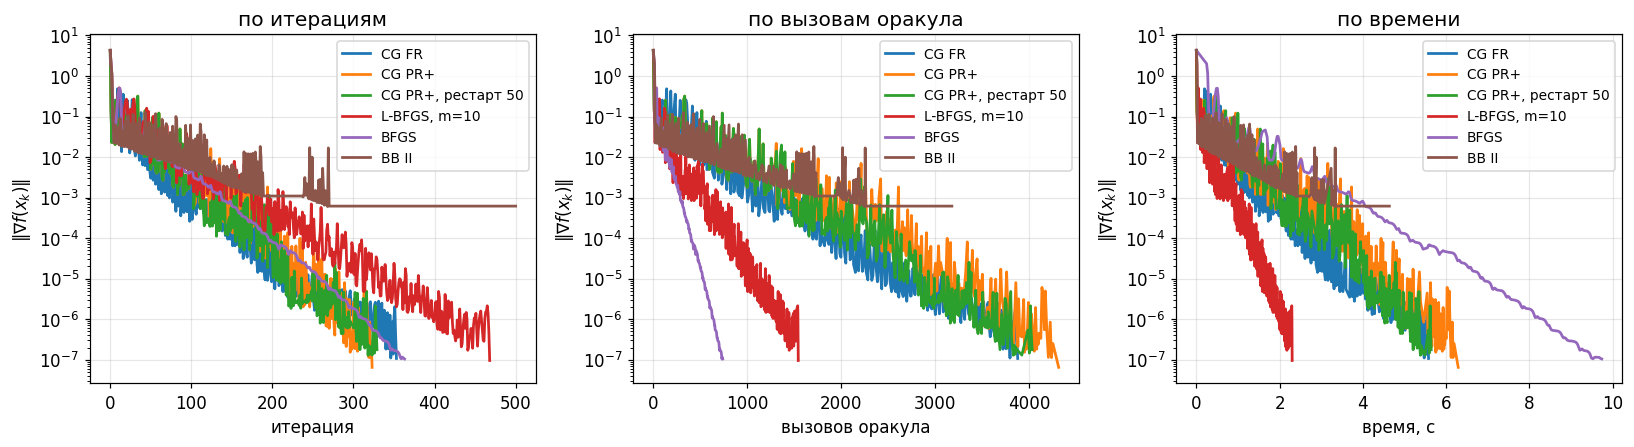

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, key, ttl in zip(axes, ["iter", "calls", "time"],
                        ["по итерациям", "по вызовам оракула", "по времени"]):
    plot_traces(traces_cmp, key, title=ttl, ax=ax)
plt.tight_layout()

По итерациям CG проигрывает, но каждая его итерация — это $O(n)$ и три вектора в
памяти против $O(mn)$ у L-BFGS и $O(n^2)$ у BFGS. Поэтому сравнивать нужно по
третьему графику, и именно там видно, где проходит граница применимости.

### 4.2. Чувствительность к параметру $c_2$

L-BFGS не портится от «ленивого» линейного поиска, CG — портится.

In [ ]:
print(f"{'метод':>12} {'c2':>6} {'итераций':>9} {'вызовов оракула':>17} {'||g||':>10}")
for c2 in [0.1, 0.4, 0.9]:
    for maker in [lambda: NonlinearCG("FR", c2=c2),
                  lambda: NonlinearCG("PR+", c2=c2),
                  lambda: LBFGS(m=10)]:
        meth = maker()
        meth.c2 = c2
        oracle_lr.reset()
        _, tr = meth.solve(oracle_lr, w0, tol=1e-7, max_iter=500)
        print(f"{tr.name:>12} {c2:6.1f} {tr.niter:9d} "
              f"{int(tr.nfs[-1] + tr.ngs[-1]):17d} {tr.gs[-1]:10.2e}")

       метод     c2  итераций   вызовов оракула      ||g||
       CG FR    0.1       353              3878   1.07e-07
      CG PR+    0.1       323              4314   6.48e-08
L-BFGS, m=10    0.1       260              2274   9.25e-08
       CG FR    0.4       485              3514   1.46e-07
      CG PR+    0.4       460              3760   1.97e-06
L-BFGS, m=10    0.4       340              1700   5.70e-08
       CG FR    0.9       500              2374   6.13e-03
      CG PR+    0.9       500              2390   2.36e-03
L-BFGS, m=10    0.9       468              1544   9.56e-08


### 4.3. Вторая задача: аналитический центр

Здесь доступен гессиан, поэтому видно, сколько именно стоит отказ от него.
Задача плохо обусловлена: $\varkappa(\nabla^2 f(x^*)) \approx 10^3$.

In [ ]:
x_star = Newton("Newton").solve(oracle_ac, x0_ac, tol=1e-10, max_iter=100)[0]
print(f"cond H(x*) = {np.linalg.cond(oracle_ac._hess(x_star)):.2e}")

traces_ac = []
for meth in [NonlinearCG("FR"), NonlinearCG("PR+"),
             NonlinearCG("PR+", c2=1e-3, name="CG PR+, c2=1e-3"),
             LBFGS(m=5), LBFGS(m=20), QuasiNewton("BFGS"), QuasiNewton("DFP"),
             BB("I"), BB("II"), Newton("Newton")]:
    oracle_ac.reset()
    _, tr = meth.solve(oracle_ac, x0_ac, tol=1e-7, max_iter=1000)
    traces_ac.append(tr)
report(traces_ac)

cond H(x*) = 1.38e+03
           метод   итер              f      ||g||  calls f  calls g  время, с
           CG FR    443  -2.010759e+02   4.90e-05     1317     1309      0.27
          CG PR+    317  -2.010759e+02   1.69e-05     1025     1017      0.14
 CG PR+, c2=1e-3    312  -2.010759e+02   2.71e-05     4530     4521      0.61
     L-BFGS, m=5    324  -2.010759e+02   1.77e-05      335      333      0.06
    L-BFGS, m=20    293  -2.010759e+02   2.08e-05      305      303      0.08
            BFGS    299  -2.010759e+02   1.30e-05      315      302      0.28
             DFP   1000  -2.010759e+02   1.01e-01     1012     1001      0.82
            BB I   1000  -2.010755e+02   6.74e-02     2267     2115      0.28
           BB II    977  -2.010759e+02   2.76e-05     2508     2498      0.35
          Newton      6  -2.010759e+02   2.48e-06        7        7      0.25


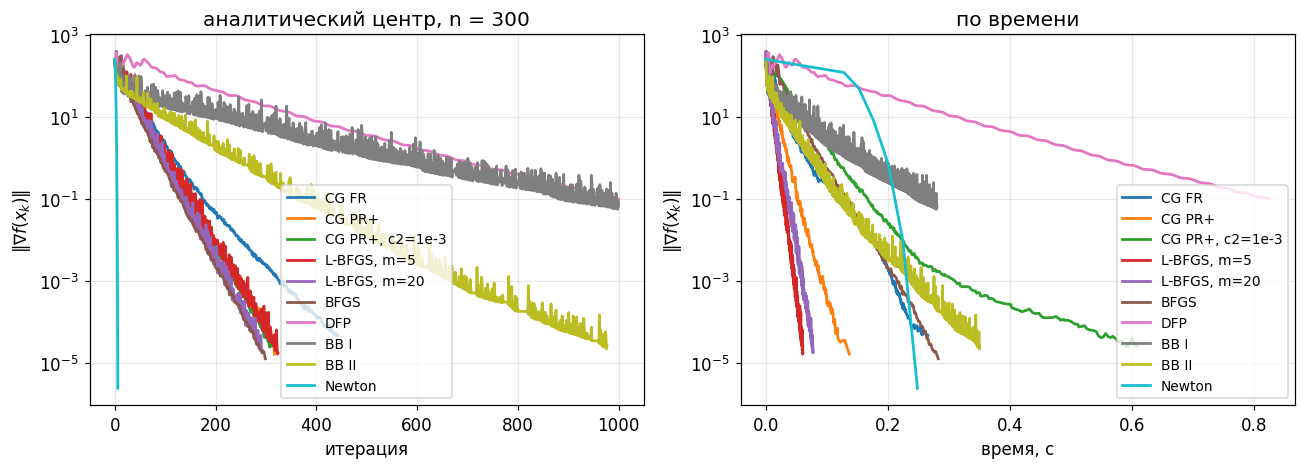

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
plot_traces(traces_ac, "iter", title="аналитический центр, n = 300", ax=axes[0])
plot_traces(traces_ac, "time", title="по времени", ax=axes[1])
plt.tight_layout()

Ньютон укладывается в единицы итераций, но каждая стоит сборки гессиана
$300\times600$ и разложения Холецкого. Квазиньютоновские методы платят
на два порядка больше итераций и всё равно выигрывают по времени,
когда $n$ велико, — ровно это и есть смысл приближения.

### 4.4. DFP против BFGS

Формулы двойственны друг другу, но ведут себя по-разному: DFP медленнее
избавляется от неверной кривизны, унаследованной от $H_0$, и сильнее страдает от
неточного линейного поиска. Смотрим на обусловленность самого приближения $H_k$.

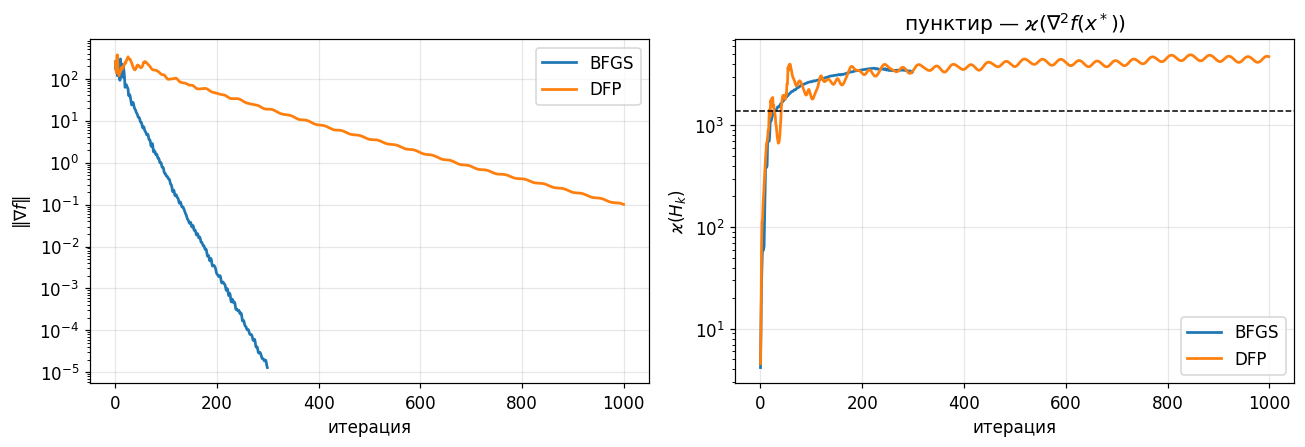

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for kind in ["BFGS", "DFP"]:
    meth = QuasiNewton(kind, track_cond=True)
    oracle_ac.reset()
    _, tr = meth.solve(oracle_ac, x0_ac, tol=1e-7, max_iter=1000)
    axes[0].semilogy(np.maximum(tr.gs, 1e-18), label=kind)
    axes[1].semilogy(meth.cond_hist, label=kind)
axes[0].set_xlabel("итерация"); axes[0].set_ylabel(r"$\|\nabla f\|$"); axes[0].legend()
axes[1].set_xlabel("итерация"); axes[1].set_ylabel(r"$\varkappa(H_k)$"); axes[1].legend()
axes[1].axhline(np.linalg.cond(oracle_ac._hess(x_star)), color="k", ls="--", lw=1)
axes[1].set_title(r"пунктир — $\varkappa(\nabla^2 f(x^*))$")
plt.tight_layout()

### 4.5. Зачем нужен пропуск пар с $s^\top y \le 0$

Пока шаг удовлетворяет условиям Вульфа, условие кривизны выполнено автоматически:
из $\langle \nabla f(x+\alpha p), p\rangle \ge c_2 \langle \nabla f(x), p\rangle$
следует $y^\top s \ge (c_2 - 1)\alpha\langle \nabla f(x), p\rangle > 0$.
Проверим, что проверка действительно ни разу не срабатывает.

In [ ]:
for orc, x0_, nm in [(oracle_lr, w0, "логрегрессия"), (rose, np.array([-1.2, 1.0]),
                                                       "Розенброк")]:
    meth = LBFGS(m=10)
    orc.reset()
    _, tr = meth.solve(orc, x0_, tol=1e-7, max_iter=300)
    print(f"{nm:>14}, Вульф:  пропущено пар {meth.n_skipped}, итераций {tr.niter}")

  логрегрессия, Вульф:  пропущено пар 0, итераций 300
     Розенброк, Вульф:  пропущено пар 0, итераций 35


Поэтому пропуск нужен ровно тогда, когда линейный поиск условие кривизны не
проверяет — то есть при обычном backtracking по Армихо, который стоит в половине
реализаций, потому что он вдвое дешевле. На невыпуклой функции это ломает метод.

In [ ]:
print(f"{'старт':>14} {'поиск':>8} {'skip':>6} {'итераций':>9} {'f':>12} "
      f"{'пропущено':>11}")
for s0 in [np.array([-1.2, 1.0]), np.array([3.0, -4.0]), np.array([-2.0, 5.0])]:
    for search in ["wolfe", "armijo"]:
        for skip in [True, False]:
            rose.reset()
            meth = LBFGS(m=10, skip=skip)
            meth.search = search
            x, tr = meth.solve(rose, s0, tol=1e-8, max_iter=1000)
            print(f"{str(s0):>14} {search:>8} {skip!s:>6} {tr.niter:9d} "
                  f"{tr.fs[-1]:12.3e} {meth.n_skipped:11d}")

         старт    поиск   skip  итераций            f   пропущено
   [-1.2  1. ]    wolfe   True        35    8.522e-22           0
   [-1.2  1. ]    wolfe  False        35    8.522e-22           0
   [-1.2  1. ]   armijo   True        46    5.061e-22           1
   [-1.2  1. ]   armijo  False         7    3.338e+00           1
     [ 3. -4.]    wolfe   True        34    5.565e-20           0
     [ 3. -4.]    wolfe  False        34    5.565e-20           0
     [ 3. -4.]   armijo   True        35    3.147e-22           0
     [ 3. -4.]   armijo  False        35    3.147e-22           0
     [-2.  5.]    wolfe   True        51    5.862e-29           0
     [-2.  5.]    wolfe  False        51    5.862e-29           0
     [-2.  5.]   armijo   True        54    2.477e-20           0
     [-2.  5.]   armijo  False        54    2.477e-20           0


## Итог

| | память | цена итерации | требования к линейному поиску |
|---|---|---|---|
| Ньютон | $O(n^2)$ | $O(n^3)$ + гессиан | мягкие, нужен $\alpha=1$ вблизи решения |
| BFGS / DFP | $O(n^2)$ | $O(n^2)$ | $c_2 = 0.9$ достаточно |
| L-BFGS | $O(mn)$ | $O(mn)$ | $c_2 = 0.9$ достаточно |
| нелинейный CG | $O(n)$ | $O(n)$ | сильные Вульфа, $c_2 \approx 0.1$ |
| BB | $O(n)$ | $O(n)$ | работает и без поиска, немонотонен |

Критические детали реализации L-BFGS: масштабирование $H^0_k$ по последней паре,
пропуск пар с $s^\top y \le 0$, старт линейного поиска с $\alpha = 1$.

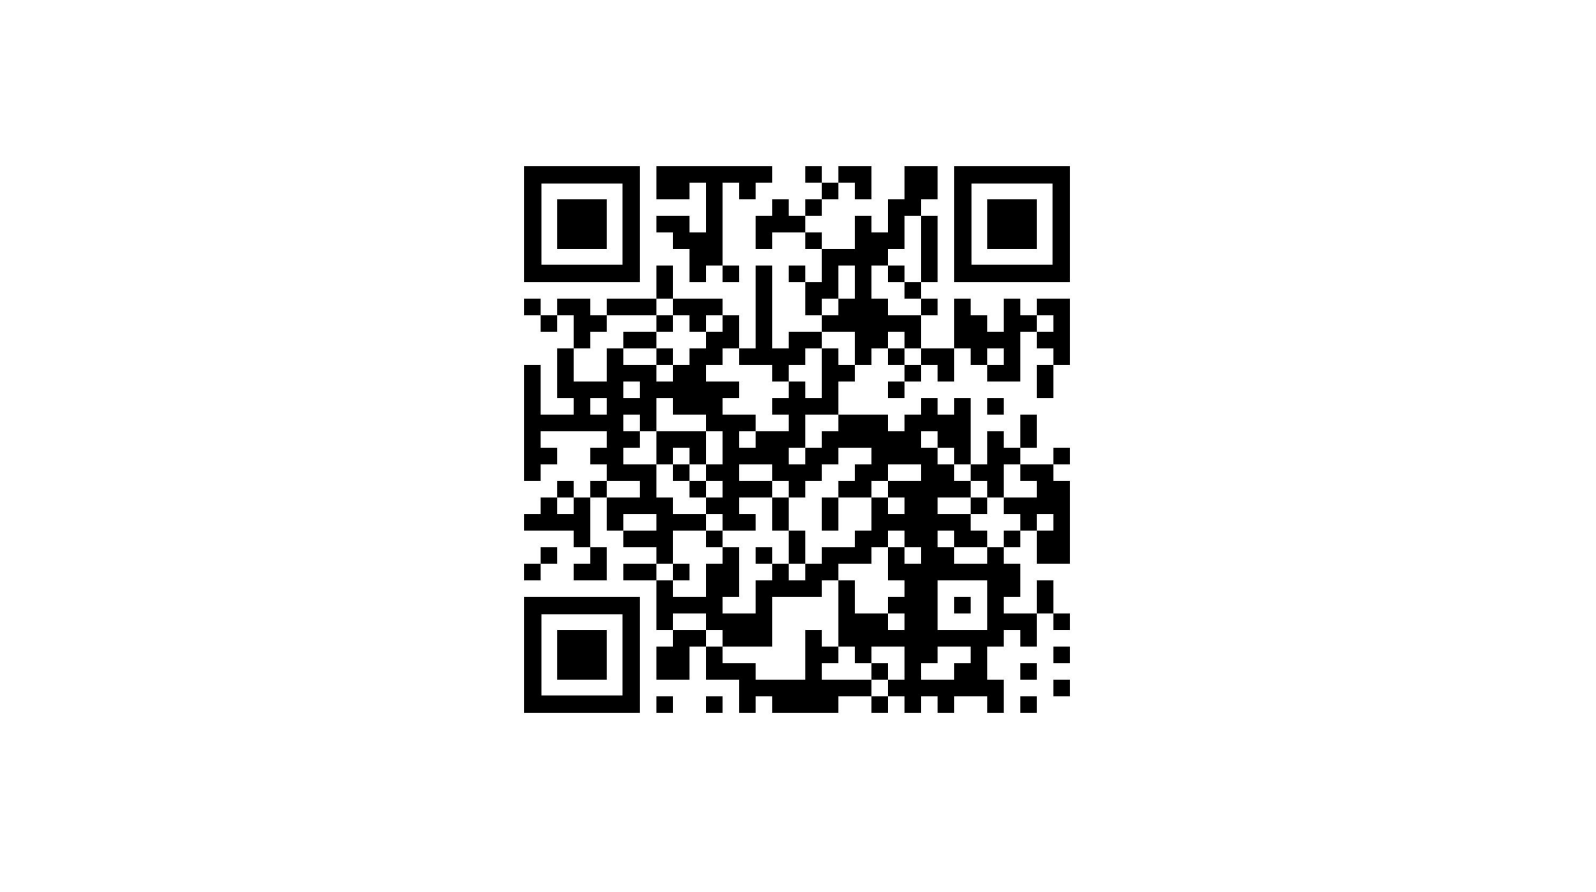